# 01 · Interpolation methods for gap filling
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mvya0005/mma3001-project-sensor-reconstruction/blob/main/notebooks/01_interpolation_methods.ipynb)

Classical, training-free reconstruction. Every choice in this notebook is made on the **validation** period (1–21 May 2024). The test period is not touched until notebook 06.

| Unit topic | Where |
|---|---|
| 2.2 Numerical errors | round-off in divided differences (float32 vs float64), conditioning of the Vandermonde matrix |
| 3.1 Interpolation and extrapolation | gap filling is interpolation; edge gaps are extrapolation (held constant, flagged) |
| 3.2 Noise and overfitting | interpolating noisy anchors vs least-squares regression; degree sweep |
| 3.3 Newton polynomial interpolation | `fill_newton` (own divided-difference table and nested evaluation) |
| 3.4 Spline interpolation | `fill_spline` (own natural cubic spline, tridiagonal solve), PCHIP |
| 3.5 2-D interpolation | `fill_grid2d` (scattered Delaunay interpolation on the day × time-of-day plane) |

In [1]:
# ---- Environment setup: works on Google Colab and locally ----
import os, sys, subprocess
from pathlib import Path

GITHUB_REPO = "mvya0005/mma3001-project-sensor-reconstruction"  # owner/name of this repository
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo_dir = Path("/content") / GITHUB_REPO.split("/")[1]
    if not repo_dir.exists():
        subprocess.run(["git", "clone", "-q", f"https://github.com/{GITHUB_REPO}.git", str(repo_dir)], check=True)
    os.chdir(repo_dir)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
    sys.path.insert(0, str(repo_dir / "src"))  # editable install is not visible until restart
    from google.colab import drive
    drive.mount("/content/drive")
    RAW = Path("/content/drive/MyDrive/MMA3001/raw")              # put the two Moodle zip files here
    PROCESSED = Path("/content/drive/MyDrive/MMA3001/processed")  # cached across Colab sessions
else:
    if Path.cwd().name == "notebooks":
        os.chdir("..")
    sys.path.insert(0, str(Path("src").resolve()))
    RAW, PROCESSED = Path("data/raw"), Path("data/processed")

PROCESSED.mkdir(parents=True, exist_ok=True)
if not (PROCESSED / "audit.json").exists():
    subprocess.run([sys.executable, "scripts/preprocess.py", "--raw", str(RAW), "--out", str(PROCESSED)], check=True)
print("repository:", Path.cwd(), "| processed data:", PROCESSED)

repository: /home/claude/mma3001-sensor-reconstruction | processed data: data/processed


In [2]:
import time
import numpy as np
import pandas as pd
from sensorfill import benchmark as bm, interpolation as itp, linalg, study, plotting
from sensorfill.plotting import plt
plotting.setup()
co2 = study.load_study(PROCESSED, "co2")
temp = study.load_study(PROCESSED, "temp")
yv, tv, _ = co2.part("val")

## 1. Why high-degree polynomials are dangerous (Runge) and how round-off enters

A gap of *L* steps filled by a single interpolating polynomial through *m* equispaced nodes behaves like Runge's example. The error *grows* with degree near the ends of the interval, which is where the gap is.

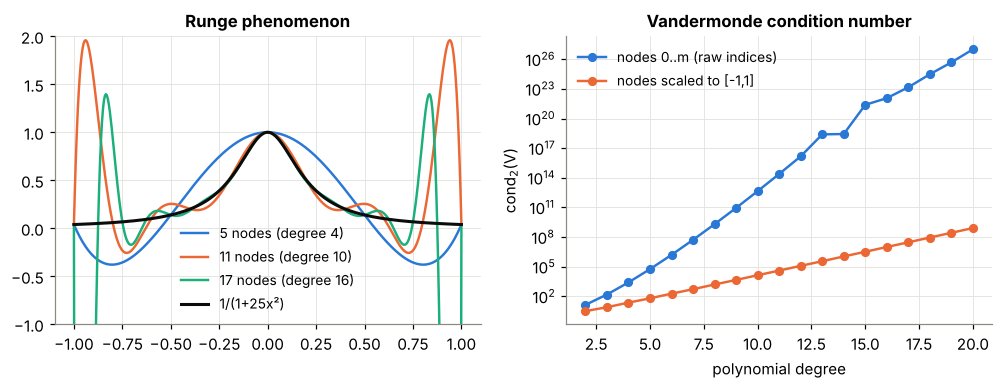

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for i, n in enumerate((5, 11, 17)):
    t, f, p = itp.runge_demo(n)
    axes[0].plot(t, p, color=plotting.PALETTE[i], label=f"{n} nodes (degree {n-1})")
axes[0].plot(t, f, color=plotting.INK, lw=2, label="1/(1+25x²)")
axes[0].set_ylim(-1, 2); axes[0].legend(); axes[0].set_title("Runge phenomenon")
# Conditioning: the monomial (Vandermonde) basis becomes ill-conditioned with degree.
degs = np.arange(2, 21)
for i, (lab, x) in enumerate({"nodes 0..m (raw indices)": None, "nodes scaled to [-1,1]": 1}.items()):
    conds = [linalg.condition_number(np.vander(np.linspace(-1, 1, d + 1) if x else np.arange(d + 1.0), increasing=True)) for d in degs]
    axes[1].semilogy(degs, conds, marker="o", color=plotting.PALETTE[i], label=lab)
axes[1].set_xlabel("polynomial degree"); axes[1].set_ylabel("cond$_2$(V)"); axes[1].legend(); axes[1].set_title("Vandermonde condition number")
_ = plotting.save(fig, "01_runge_conditioning")

The Newton divided-difference form never builds *V*, and `fill_newton` additionally rescales the nodes to [-1, 1]. Round-off is a separate risk that comes from **how time is stored**. Raw timestamps are Unix seconds (≈ 1.7 × 10⁹). In float32 the spacing between representable numbers at that size is 128 s, so 10-minute nodes are corrupted before any arithmetic happens. The cell below interpolates a smooth CO₂-like curve through 8 nodes, 600 s apart, and compares the result with the exact value.

In [4]:
def newton_at_mid(dtype, relative_time, m=8):
    T0 = 1_714_521_600.0                      # 1 May 2024 as Unix seconds
    x = T0 + 600.0 * np.arange(m)
    f = 450 + 50 * np.sin(np.pi * (x - T0) / (600 * m))
    t = T0 + 600 * 3.5
    if relative_time:                          # measure time from the first node
        x, t = x - T0, t - T0
    xs, fs, ts_ = x.astype(dtype), f.astype(dtype), np.array([t], dtype)
    c = fs.copy()
    with np.errstate(all="ignore"):
        for j in range(1, m):                  # divided-difference table in the chosen precision
            c[j:] = (c[j:] - c[j - 1:-1]) / (xs[j:] - xs[: m - j])
        p = np.full_like(ts_, c[-1])
        for k in range(m - 2, -1, -1):         # nested (Horner) evaluation
            p = p * (ts_ - xs[k]) + c[k]
    return float(p[0])

exact = 450 + 50 * np.sin(np.pi * 3.5 / 8)
pd.DataFrame([{"precision": dt.__name__, "time axis": "relative" if rel else "raw Unix seconds",
               "abs error [ppm]": abs(newton_at_mid(dt, rel) - exact)}
              for dt in (np.float32, np.float64) for rel in (False, True)])

,precision,time axis,abs error [ppm]
0,float32,raw Unix seconds,0.384631
1,float32,relative,0.000018
2,float64,raw Unix seconds,0.000029
3,float64,relative,0.000029


The float64 error (≈ 3 × 10⁻⁵ ppm) is the *truncation* error of a degree-7 interpolant. float32 with raw timestamps adds a *round-off* error about 10⁴ times larger (≈ 0.4 ppm). With a relative time axis, float32 is fine again. The package therefore works in float64 on integer step indices. In notebook 05 (float32 on the GPU), all inputs are standardised to order one for the same reason.

## 2. What the methods do on one real gap (6 hours, validation period)

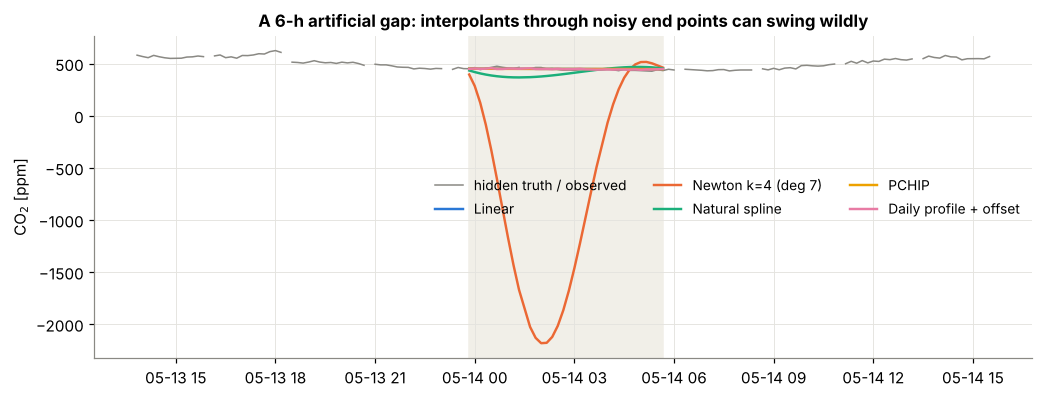

In [5]:
from sensorfill.masking import block_mask, apply_mask
rng = np.random.default_rng(3)
mask = block_mask(~np.isnan(yv), 36, 1, rng, margin=2, min_observed=0.8)
y_in = apply_mask(yv, mask)
gap = np.flatnonzero(mask)
win = slice(gap[0] - 60, gap[-1] + 60)
ctx = bm.Context(ts=tv, profile=co2.train_profile)
show = {"Linear": itp.fill_linear(y_in), "Newton k=4 (deg 7)": itp.fill_newton(y_in, 4),
        "Natural spline": itp.fill_spline(y_in), "PCHIP": itp.fill_pchip(y_in),
        "Daily profile + offset": itp.fill_profile(y_in, tv, co2.train_profile)}
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(tv[win], yv[win], color=plotting.MUTED, lw=1, label="hidden truth / observed")
for i, (k, v) in enumerate(show.items()):
    ax.plot(tv[gap], v[gap], color=plotting.PALETTE[i], label=k)
ax.axvspan(tv[gap[0]], tv[gap[-1]], color="#f1efe8", zorder=-1)
ax.set_ylabel("CO$_2$ [ppm]"); ax.legend(ncol=3); ax.set_title("A 6-h artificial gap: interpolants through noisy end points can swing wildly")
_ = plotting.save(fig, "01_one_gap")

## 3. Noise and overfitting: interpolation vs regression

Interpolation forces the curve through the anchor readings, *including their noise*. Higher-order interpolants also amplify the noise in the end slopes. That is overfitting in the sense of topic 3.2. Two remedies are tested below:

* **Robust anchors.** Average *k* readings at each gap end. This lowers the anchor variance from σ² to σ²/k but adds bias if the signal is curved.
* **Local least-squares regression** (`fill_local_poly`). Fit, rather than interpolate, a low-degree polynomial to *k* readings on each side.

Both are tuned on the validation set, scoring RMSE on the hidden points over 3 random mask draws × 30 gaps per length.

In [6]:
cands = {"Linear (k=1)": lambda y, c: itp.fill_linear(y)}
for k in (2, 3, 5, 8):
    cands[f"Robust linear k={k}"] = (lambda k: lambda y, c: itp.fill_linear_robust(y, k))(k)
for k, d in ((6, 1), (6, 2), (12, 2)):
    cands[f"Local LSQ k={k} deg={d}"] = (lambda k, d: lambda y, c: itp.fill_local_poly(y, k, d))(k, d)
for k in (2, 3, 4):
    cands[f"Newton k={k} (deg {2*k-1})"] = (lambda k: lambda y, c: itp.fill_newton(y, k))(k)
res_noise = bm.run_benchmark(yv, ctx, cands, gap_lengths=study.GAP_LENGTHS, repeats=3, seed=1)
tab = bm.summarise(res_noise).round(1)
tab

gap_len,1,3,6,18,36,72,144
method,,,,,,,
Robust linear k=8,12.0,12.1,14.6,17.5,22.8,34.3,45.4
Robust linear k=2,9.3,10.1,12.2,15.8,20.0,31.7,45.7
Robust linear k=3,9.3,10.3,12.9,16.0,20.4,32.3,45.7
Local LSQ k=6 deg=1,11.3,11.1,13.8,16.6,21.5,33.8,45.8
Robust linear k=5,10.5,10.8,13.5,16.1,21.2,33.2,45.8
Linear (k=1),9.5,10.1,12.5,15.9,20.1,31.0,46.2
Local LSQ k=12 deg=2,11.2,10.9,13.6,16.9,23.2,39.8,65.1
Local LSQ k=6 deg=2,9.2,10.4,13.0,17.9,27.7,33.7,77.1
Newton k=2 (deg 3),10.9,12.5,18.9,32.6,64.4,118.5,261.4


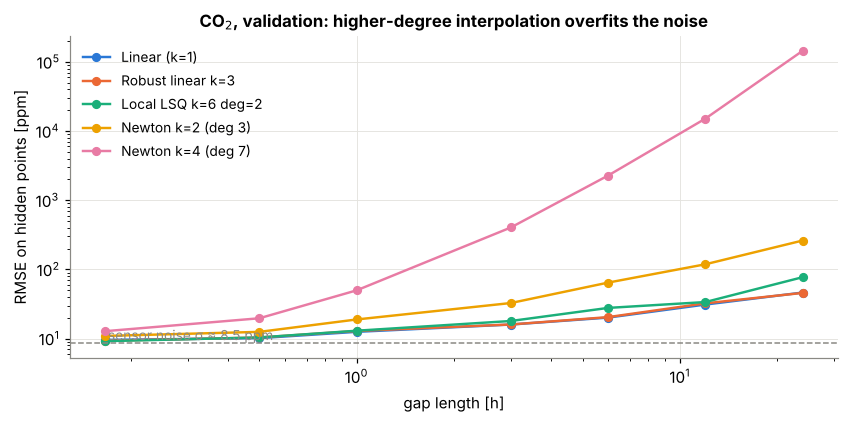

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, name in enumerate(["Linear (k=1)", "Robust linear k=3", "Local LSQ k=6 deg=2", "Newton k=2 (deg 3)", "Newton k=4 (deg 7)"]):
    m = res_noise[res_noise.method == name].groupby("gap_len").rmse.mean()
    ax.plot(m.index * 10 / 60, m.values, marker="o", color=plotting.PALETTE[i], label=name)
ax.axhline(8.5, color=plotting.MUTED, ls="--", lw=1); ax.text(0.17, 9.5, "sensor noise σ ≈ 8.5 ppm", color=plotting.MUTED, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("gap length [h]"); ax.set_ylabel("RMSE on hidden points [ppm]")
ax.set_title("CO$_2$, validation: higher-degree interpolation overfits the noise"); ax.legend()
_ = plotting.save(fig, "01_noise_overfitting")

**Reading the result.**
* High-degree Newton interpolation is the worst method at every gap length. Its error grows by orders of magnitude with gap length: this is overfitting to noisy nodes combined with Runge-type growth.
* Averaging 2–3 readings at each end changes the short-gap RMSE by only a few tenths of a ppm, which is within the variation between mask draws. Larger *k* clearly hurts, because bias from the signal's curvature outweighs the reduced noise. The white-noise theory predicted a larger gain. The difference suggests that much of the sample-to-sample variation is real, fast signal (ventilation and door events) rather than pure sensor noise, so σ ≈ 8.5 ppm overestimates the noise. **Decision:** plain linear stays the reference baseline. Robust linear (k = 3) is kept as the base that the ML models in notebook 04 correct, because a slightly smoother base gives them a less noisy target.
* No interpolant beats ≈ 8 ppm RMSE for 10-minute gaps, because that is the noise floor estimated in notebook 00.

## 4. Two-dimensional interpolation on the day × time-of-day plane

Folding the series into an image (rows = days, columns = 10-min slot of the day) turns daily repetition into vertical structure. A missing block can then be interpolated from the *same time on neighbouring days* as well as from neighbouring times, using `scipy.interpolate.griddata` (Delaunay triangulation for linear and cubic). The day axis is scaled so that one day is "as far as" one hour, a tunable assumption.

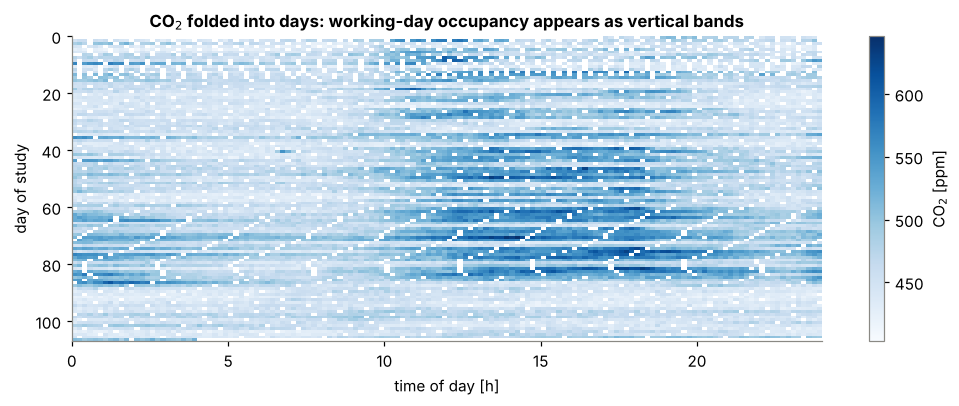

In [8]:
M = linalg.fold_daily(co2.y, study.STEPS_PER_DAY, bm.Context(ts=co2.ts).midnight_offset)
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(M, aspect="auto", cmap="Blues", interpolation="nearest", extent=[0, 24, M.shape[0], 0])
ax.set_xlabel("time of day [h]"); ax.set_ylabel("day of study"); ax.grid(False)
fig.colorbar(im, ax=ax, label="CO$_2$ [ppm]"); ax.set_title("CO$_2$ folded into days: working-day occupancy appears as vertical bands")
_ = plotting.save(fig, "01_daily_image")

In [9]:
two_d = {"Linear": lambda y, c: itp.fill_linear(y)}
for meth in ("nearest", "linear", "cubic"):
    two_d[f"griddata {meth}"] = (lambda m: lambda y, c: itp.fill_grid2d(y, c.steps_per_day, c.midnight_offset, m))(meth)
res2d = {}
for s in (co2, temp):
    yv_s, tv_s, _ = s.part("val")
    res2d[s.variable] = bm.summarise(bm.run_benchmark(yv_s, bm.Context(ts=tv_s), two_d, repeats=2, seed=2)).round(3)
pd.concat(res2d, names=["variable"])

gap_len                       1       3       6       18      36      72   \
variable method                                                             
co2      griddata linear   13.615  13.137  14.378  28.026  32.649  39.954   
         griddata cubic    16.751  17.425  21.259  34.650  41.998  53.296   
         griddata nearest  11.040  13.744  17.401  33.168  39.352  45.704   
         Linear             9.614  10.701  14.503  17.424  20.644  34.792   
temp     griddata linear    0.107   0.127   0.127   0.364   0.459   0.563   
         griddata nearest   0.182   0.207   0.224   0.453   0.563   0.691   
         griddata cubic     0.112   0.157   0.173   0.435   0.520   0.715   
         Linear             0.102   0.121   0.126   0.341   0.751   1.301   

gap_len                       144  
variable method                    
co2      griddata linear   40.731  
         griddata cubic    44.651  
         griddata nearest  44.684  
         Linear            46.178  
temp     griddata linear    0.565  
         griddata nearest   0.632  
         griddata cubic     0.668  
         Linear             1.741

## 5. Validation summary of all interpolation methods (CO₂ and temperature)

In [10]:
methods = {k: v for k, v in bm.classical_methods().items() if not k.startswith(("Laplace", "SVD"))}
methods["Robust linear k=3"] = lambda y, c: itp.fill_linear_robust(y, 3)
val_tables = {}
for s in (co2, temp):
    yv_s, tv_s, _ = s.part("val")
    r = bm.run_benchmark(yv_s, bm.Context(ts=tv_s, profile=s.train_profile), methods, repeats=3, seed=4)
    val_tables[s.variable] = r
    print(f"\n{s.variable} [{s.unit}] - mean RMSE on hidden validation points")
    display(bm.summarise(r).round(3))
pd.concat(val_tables, names=["variable"]).to_csv("reports/val_interpolation.csv")


co2 [ppm] - mean RMSE on hidden validation points


gap_len,1,3,6,18,36,72,144
method,,,,,,,
Daily profile + offset,10.578,11.563,13.727,14.769,19.704,23.111,29.850
2-D griddata (day x tod),12.233,12.727,15.039,28.681,32.179,38.728,42.296
Linear,9.886,10.484,12.908,14.990,23.578,32.882,44.816
Robust linear k=3,10.150,10.872,13.044,15.265,23.654,32.834,44.858
LOCF,11.352,14.335,19.816,23.121,36.004,48.542,45.431
PCHIP,10.032,11.033,13.690,16.164,25.818,33.469,45.846
"Newton (k=2, cubic)",10.815,13.203,17.607,35.245,66.694,133.055,273.725
Natural spline,11.598,15.470,20.779,47.453,89.961,182.761,371.124
"Newton (k=4, deg 7)",12.251,21.131,45.565,424.998,2426.500,16380.100,110936.084



temp [degC] - mean RMSE on hidden validation points


gap_len,1,3,6,18,36,72,144
method,,,,,,,
2-D griddata (day x tod),0.100,0.113,0.147,0.452,0.501,0.664,0.645
Daily profile + offset,0.111,0.128,0.142,0.293,0.446,0.758,0.859
Robust linear k=3,0.107,0.157,0.164,0.529,0.726,1.337,1.704
Linear,0.096,0.108,0.143,0.473,0.678,1.318,1.705
PCHIP,0.101,0.115,0.151,0.393,0.657,1.319,1.717
LOCF,0.173,0.245,0.327,0.895,1.280,1.848,1.746
"Newton (k=2, cubic)",0.107,0.127,0.165,0.420,0.925,1.733,2.886
Natural spline,0.116,0.147,0.191,0.485,1.101,1.823,3.473
"Newton (k=4, deg 7)",0.123,0.197,0.374,3.593,21.527,138.057,1063.536


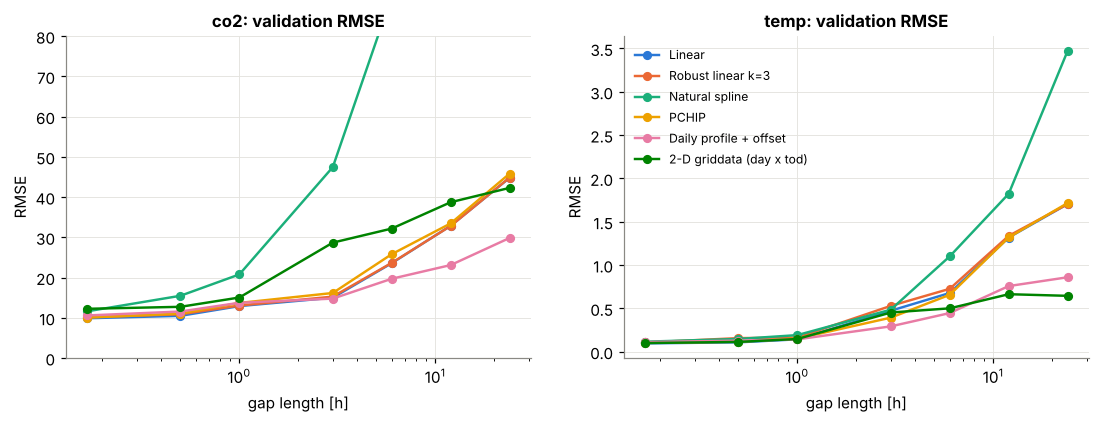

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
keep = ["Linear", "Robust linear k=3", "Natural spline", "PCHIP", "Daily profile + offset", "2-D griddata (day x tod)"]
for ax, (var, r) in zip(axes, val_tables.items()):
    for i, name in enumerate(keep):
        m = r[r.method == name].groupby("gap_len").rmse.mean()
        ax.plot(m.index * 10 / 60, m.values, marker="o", color=plotting.PALETTE[i], label=name)
    ax.set_xscale("log"); ax.set_xlabel("gap length [h]"); ax.set_ylabel("RMSE"); ax.set_title(f"{var}: validation RMSE")
axes[0].set_ylim(0, 80); axes[1].legend(fontsize=8)
_ = plotting.save(fig, "01_val_summary")

### Conclusions carried forward
1. **Short gaps (≤ 1 h).** Linear interpolation is as good as anything here, at about 10 ppm, close to the noise floor. Cubic methods add nothing and start to overshoot.
2. **Long gaps (6 h and more).** Methods that use *daily periodicity* win (at 3 h, the profile and linear are tied). For **CO₂** the daily profile with offset correction cuts the 12–24 h error of linear interpolation by about a third. 2-D griddata is *worse* than linear at intermediate lengths, because CO₂ varies a lot from one day to the next. For **temperature**, whose daily cycle is regular, 2-D griddata and the profile cut the 24 h error by a factor of 2–3.
3. **Local polynomials** (spline, Newton) are unusable beyond about an hour. They are kept only as documented failure cases of overfitting.
4. **Edge gaps** (no observation after the gap) are extrapolation. All methods hold the last value there. Such gaps are flagged and never scored.
5. **Carried to the final benchmark:** Linear (reference), PCHIP, Daily profile + offset and 2-D griddata (linear).